# El plan de capital: ingreso neto antes de provisiones, la trayectoria de CET1, el balance estático de la EBA y la pila de capital chilena

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 04 de este tema (los escenarios y las tasas de pérdida que implican)
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- construir la trayectoria de CET1 a tres años de un escenario de estrés a partir del capital inicial y las pérdidas del cuaderno 04, con y sin una fila rotulada de ingreso neto antes de provisiones (PPNR), y decir por qué el capital principal es la trayectoria de solo pérdidas;
- calcular el objetivo interno de capital chileno (el OI), sus componentes y el tope de 4 por ciento que limita el requerimiento del artículo 66 quinquies y no la estimación propia del banco, y el mínimo legal frente al que se prueba el plan;
- correr los tres casos del plan (base, estrés sin mitigación, estrés con mitigación) con `capital_plan`, y leer por qué el banco bajo estrés puede mantener el mínimo legal y aun así no alcanzar su propio objetivo interno;
- aplicar las reglas de balance estático de la EBA 2025 a los saldos por etapa y hacer que la prueba del motor detecte una cura y un cambio del total;
- calcular la aproximación de Contraste de la guía de Pilar 2, y reconstruir las 34 filas del formulario resumen del Anexo 3 de la CMF, comparando cada fila con las versionadas.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un cuaderno nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del cuaderno que falla si el motor cambia el texto.

Este cuaderno lee además un archivo de constantes del pipeline del producto, `data-pipeline/pipeline/cases/c18/params.py` (la asignación de los seis segmentos de C07 a las tres clases de préstamo). El pipeline es un conjunto de scripts y no un paquete, así que el cuaderno carga ese único archivo por su ruta con la biblioteca estándar: una sola fuente para la asignación, nunca una copia. El archivo no tiene dependencias.

La celda siguiente importa lo que usa el cuaderno e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importar el motor y las ayudas, e imprimir las versiones de los paquetes que usa este cuaderno
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import importlib.util

import matplotlib.pyplot as plt
from riskvalidation.stress import capital
from riskvalidation.validation import stress as stress_tests
for name in ("riskvalidation", "numpy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Este cuaderno lee el lado de capital de **C18** (Banco Andino).

- **Propietario y licencia:** los documentos los escribe el pipeline sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este cuaderno son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este cuaderno, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` y `fed-2026-severely-adverse.json` (`outputs.capital_start`, `losses`, `internal_capital_target`, `headline_cet1`, `capital_plan`, `p2g_proxy`, `annex3`), el documento de modelos `models-banco-andino.json` (la pila chilena, las reglas de la EBA por párrafo), `reverse-stress.json` (la pila del punto de falla) y, para el balance estático, los saldos por etapa y los parámetros de segmento del caso de provisiones C07 (`data/derived/C07/base.json` y `models-banco-andino.json`) y la asignación de segmento a clase de `data-pipeline/pipeline/cases/c18/params.py`.
- **El capital de Banco Andino es un ancla, no un balance.** El CET1 es el proxy de Tier 1 del caso de tasas C15; los activos ponderados por riesgo (APR) son ese proxy sobre el ancla de CET1 de 11,0 por ciento, repartidos entre riesgo de crédito, de mercado y operacional según la mezcla del Formulario 20-F 2025 de un banco chileno grande (solo razones, porque el documento es solo derivado). La parte del patrimonio efectivo sobre el CET1 se lleva como Tier 2 y el AT1 es nulo, un supuesto **NO VERIFICADO** en las fuentes y rotulado así en el documento. El dinero está en millones de CLP y las proporciones son proporciones de los APR.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; un archivo ausente detiene el cuaderno y nombra su ruta
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


def sino(valor):
    # Mostrar un valor verdadero o falso como "sí" o "no"
    return "sí" if valor else "no"


print("carpeta derived encontrada:", sino(DERIVED.is_dir()))

baseline = read_json("C18/baseline.json")["outputs"]
fed_doc = read_json("C18/fed-2026-severely-adverse.json")
fed = fed_doc["outputs"]
models = read_json("C18/models-banco-andino.json")["fit"]
start = fed["capital_start"]
print("horneado con riskvalidation", fed_doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("punto de partida:", fed["bank"]["as_of"], "| APR:", round(start["rwa_clp_m"], 1), "| CET1:", round(start["cet1_clp_m"], 1), "| razón de CET1:", start["cet1_ratio"], "| razón de PE:", round(start["pe_ratio"], 6))
print("APR por riesgo:", {k: round(v, 0) for k, v in start["rwa_by_risk"].items()}, "| AT1:", start["at1_clp_m"], "| T2:", round(start["t2_clp_m"], 1))

carpeta derived encontrada: sí
horneado con riskvalidation 0.9.0 | instalado 0.9.0
punto de partida: 2026-08-31 | APR: 7492853.0 | CET1: 824213.8 | razón de CET1: 0.11 | razón de PE: 0.168938
APR por riesgo: {'credit': 5307997.0, 'market': 1283189.0, 'operational': 901667.0} | AT1: 0.0 | T2: 441613.8


## Método

### Paso 1: la trayectoria principal, el CET1 menos las pérdidas

La trayectoria de CET1 **principal** del caso es el **agotamiento de solo pérdidas**: el CET1 del punto de partida menos las pérdidas con estrés acumuladas de los años transcurridos, sin inventar ingresos,

$$\mathrm{CET1}_y = \mathrm{CET1}_0 - \sum_{s \le y} L_s, \qquad y = 1, 2, 3.$$

La pérdida de un año es la suma de la pérdida de crédito del cuaderno 04 y las pérdidas esperadas de los demás riesgos: mercado y riesgo operacional no tienen libro de posiciones ni mapa macro en el caso, así que cada uno lleva su pérdida esperada anual en todo escenario y la pérdida con estrés es un piso. La pérdida de IRRBB es nula porque un cambio de valor económico no es una partida de resultados de la cartera de inversión; la trayectoria de tasas actúa en cambio sobre el margen financiero neto (paso 2). `cet1_path_loss_only(cet1_0, losses)` calcula la trayectoria. La celda siguiente lee las pérdidas del escenario severamente adverso, construye la trayectoria y compara con las filas principales versionadas.

In [3]:
# La trayectoria de CET1 de solo pérdidas del escenario severamente adverso frente a las filas principales versionadas
loss_rows = fed["losses"]["scenario_losses"]
losses = [row["total"] for row in loss_rows]
for row in loss_rows:
    print(f'año {row["year"]}: crédito {row["credit"]:10,.0f} + mercado {row["market"]:.0f} + IRRBB {row["irrbb"]:.0f} + operacional {row["operational"]:8,.0f} = total {row["total"]:10,.0f}')
path = capital.cet1_path_loss_only(start["cet1_clp_m"], losses)
committed_rows = fed["headline_cet1"]["rows"]
print("trayectoria de CET1 (motor):", np.round(path, 1))
print("versionada                 :", np.round([row["cet1_clp_m"] for row in committed_rows], 1))
print("razón de CET1 por año      :", np.round(path / start["rwa_clp_m"], 4), "| método:", fed["headline_cet1"]["method"])

año 1: crédito     86,519 + mercado 0 + IRRBB 0 + operacional    1,188 = total     87,706
año 2: crédito    111,987 + mercado 0 + IRRBB 0 + operacional    1,188 = total    113,174
año 3: crédito     71,005 + mercado 0 + IRRBB 0 + operacional    1,188 = total     72,193
trayectoria de CET1 (motor): [736507.7 623333.4 551140.8]
versionada                 : [736507.7 623333.4 551140.8]
razón de CET1 por año      : [0.0983 0.0832 0.0736] | método: loss-only-depletion


### Paso 2: la fila rotulada de PPNR

Un banco gana mientras pierde. El caso agrega una **fila rotulada** con el ingreso neto antes de provisiones, nunca el capital principal. El margen financiero neto (NII) de cada año sigue la trayectoria de tasas del escenario a través del motor de tasas de interés del tema 09 sobre la cartera de C15; los ingresos por comisiones y el costo operacional son dos razones constantes declaradas, supuestos del caso y no cifras de Banco Andino ni de la CMF:

$$\text{comisiones} = r_{\text{com}}\cdot\mathrm{NII},\qquad \text{costo} = r_{\text{costo}}\,(\mathrm{NII} + \text{comisiones}),\qquad \mathrm{PPNR} = \mathrm{NII} + \text{comisiones} - \text{costo},$$

con $r_{\text{com}} = 0,25$ y $r_{\text{costo}} = 0,55$. Los dossiers no documentan un modelo de PPNR de la Reserva Federal; su elemento de razón de eficiencia es solo el precedente de una razón de costo. `ppnr_row(nii, fee_ratio, cost_ratio)` calcula la fila. La celda siguiente recalcula los tres años del escenario severamente adverso a partir del NII versionado, imprime cada paso y compara con las filas versionadas, incluido el CET1 con PPNR.

In [4]:
# Recalcular la fila de PPNR de cada año con el NII versionado y las dos razones declaradas, y el CET1 con PPNR
ppnr = fed["headline_cet1"]["ppnr"]
fee_ratio, cost_ratio = ppnr["fee_ratio"]["value"], ppnr["cost_ratio"]["value"]
print("razón de comisiones:", fee_ratio, "| razón de costo:", cost_ratio, "| rótulos:", ppnr["fee_ratio"]["label"], "y", ppnr["cost_ratio"]["label"])
cumulative = 0.0
for k, row in enumerate(ppnr["rows"]):
    mine = capital.ppnr_row(row["nii_clp_m"], fee_ratio, cost_ratio)
    cumulative += mine.ppnr
    cet1_with = path[k] + cumulative
    print(f'año {row["year"]}: NII {mine.nii:9,.0f} + comisiones {mine.fee_income:8,.0f} - costo {mine.operating_cost:9,.0f} = PPNR {mine.ppnr:9,.0f} | CET1 con PPNR {cet1_with:10,.0f} (versionado {row["cet1_with_ppnr_clp_m"]:10,.0f}) | razón {cet1_with / start["rwa_clp_m"]:.4f}')

razón de comisiones: 0.25 | razón de costo: 0.55 | rótulos: case assumption y case assumption
año 1: NII   262,778 + comisiones   65,695 - costo   180,660 = PPNR   147,813 | CET1 con PPNR    884,320 (versionado    884,320) | razón 0.1180
año 2: NII   261,458 + comisiones   65,364 - costo   179,752 = PPNR   147,070 | CET1 con PPNR    918,216 (versionado    918,216) | razón 0.1225
año 3: NII   261,458 + comisiones   65,364 - costo   179,752 = PPNR   147,070 | CET1 con PPNR    993,093 (versionado    993,093) | razón 0.1325


### Paso 3: el objetivo interno de capital y el mínimo legal

En el marco IAPE de Chile (CMF RAN 21-13, Capítulo 21-13 sección I; dossier 03) un banco fija un **objetivo interno** de patrimonio efectivo sobre APR,

$$\mathrm{OI} \;\ge\; 8\% + c_{\mathrm{DSIB}} + c_{P2} + c_{\mathrm{CCoB}} + c_{\mathrm{CCyB}} + c_d,$$

el mínimo de 8 por ciento más el colchón de banco sistémico, la estimación propia del banco de Pilar 2, los colchones de conservación y contracíclico y un colchón voluntario de estrés $c_d$ (que puede ser cero). El término de Pilar 2 tiene dos cosas distintas: el **requerimiento del artículo 66 quinquies** $p2r$, que fija la CMF y que la ley limita a **4 por ciento de los APR**, y la estimación propia del banco $c_{P2} \ge p2r$, que no tiene tope. `internal_capital_target` del motor hace cumplir ambos hechos. El mínimo legal frente al que se prueba el estrés es $8\% + c_{\mathrm{DSIB}} + p2r$.

La celda siguiente construye el objetivo con los componentes versionados, imprime cada uno y muestra al motor rechazando un requerimiento sobre el tope y una estimación propia bajo el requerimiento. Luego calcula `chilean_cet1_stack`, el CET1 mínimo sobre APR de la pila legal ($4,5\% + 2,5\% + \text{CCyB} + c_{\mathrm{DSIB}} + $ la parte de CET1 del Pilar 2), con la parte que usa la prueba de estrés inverso del cuaderno 06.

In [5]:
# Construir el objetivo interno y el mínimo legal con los componentes versionados; mostrar los dos rechazos; calcular la pila de CET1
target = fed["internal_capital_target"]
stack = models["bank_anchors"]["chilean_stack"]
oi = capital.internal_capital_target(target["c_dsib"], target["c_p2"]["value"], target["c_ccob"], target["c_ccyb"], target["c_d"]["value"], p2r=stack["p2r"])
print("componentes:", {"min_pe": oi.min_pe, "c_dsib": oi.c_dsib, "c_p2 (estimación propia)": oi.c_p2, "c_ccob": oi.c_ccob, "c_ccyb": oi.c_ccyb, "c_d": oi.c_d, "p2r (art. 66 quinquies)": oi.p2r})
print("OI:", round(oi.oi, 6), "| versionado:", round(target["oi"], 6), "| rótulos de c_p2 y c_d:", target["c_p2"]["label"], "y", target["c_d"]["label"])
legal_minimum = oi.min_pe + oi.c_dsib + oi.p2r
print("mínimo legal (8% + c_DSIB + p2r):", round(legal_minimum, 6), "| requerimiento versionado de los casos de estrés:", fed["capital_plan"]["cases"][1]["years"][0]["requirement"]["pct_of_rwa"])
# el motor escribe sus mensajes en inglés; la tabla da su traducción y falla (KeyError) si el motor cambia el texto
TRADUCCION = {
    "p2r = 0.05 is above the 0.04 cap of RWA on the art. 66 quinquies requirement (03 l.253)": "p2r = 0.05 supera el tope de 0.04 de los APR para el requerimiento del art. 66 quinquies (03 l.253)",
    "c_p2 = 0.01 is below p2r = 0.02: the bank's estimate includes the art. 66 quinquies requirement": "c_p2 = 0.01 es menor que p2r = 0.02: la estimación propia del banco incluye el requerimiento del art. 66 quinquies",
}
for why, kwargs in (("p2r sobre el tope de 4 por ciento", dict(p2r=0.05, c_p2=0.05)), ("estimación propia bajo p2r", dict(p2r=0.02, c_p2=0.01))):
    try:
        capital.internal_capital_target(target["c_dsib"], kwargs["c_p2"], target["c_ccob"], target["c_ccyb"], target["c_d"]["value"], p2r=kwargs["p2r"])
    except ValueError as err:
        print(f"{why}: rechazado: {TRADUCCION[str(err)]}")
reverse = read_json("C18/reverse-stress.json")["outputs"]["failure_point"]["stack"]
print("pila de CET1 con la parte del estrés inverso:", round(capital.chilean_cet1_stack(reverse["c_ccyb"], reverse["c_dsib"], reverse["p2_cet1"]["value"]), 6), "| versionada:", reverse["total"])

componentes: {'min_pe': 0.08, 'c_dsib': 0.015, 'c_p2 (estimación propia)': 0.01, 'c_ccob': 0.025, 'c_ccyb': 0.005, 'c_d': 0.01, 'p2r (art. 66 quinquies)': 0.00125}
OI: 0.145 | versionado: 0.145 | rótulos de c_p2 y c_d: case assumption y case assumption
mínimo legal (8% + c_DSIB + p2r): 0.09625 | requerimiento versionado de los casos de estrés: 0.09625
p2r sobre el tope de 4 por ciento: rechazado: p2r = 0.05 supera el tope de 0.04 de los APR para el requerimiento del art. 66 quinquies (03 l.253)
estimación propia bajo p2r: rechazado: c_p2 = 0.01 es menor que p2r = 0.02: la estimación propia del banco incluye el requerimiento del art. 66 quinquies
pila de CET1 con la parte del estrés inverso: 0.090625 | versionada: 0.09062500000000001


### Paso 4: los tres casos del plan

`capital_plan(rwa, cet1_0, at1, t2, base_cet1, stress_losses, mitigation_effects, oi, legal_minimum)` devuelve, para tres años, los tres casos de la proyección IAPE (dossier 03):

- **base:** CET1 de la trayectoria base del llamador (el CET1 del escenario base con su PPNR), probado frente al objetivo interno OI;
- **estrés sin mitigación:** la trayectoria de solo pérdidas del paso 1, probada frente al mínimo legal;
- **estrés con mitigación:** la misma trayectoria más las acciones de mitigación acumuladas.

Bajo el **balance estático** de las reglas de la EBA los APR son los mismos cada año, el AT1 y el Tier 2 quedan en sus valores de partida, y no se permite ninguna medida de capital después de la fecha de referencia. Las fuentes no nombran ninguna acción de mitigación, así que el caso no supone ninguna (el caso con mitigación es igual al sin ella y la fila 10.2 del Anexo 3 no aplica). La holgura de un año es la razón de patrimonio efectivo menos el requerimiento, y el déficit es $\max(0, \text{requerimiento}\cdot\mathrm{APR} - \mathrm{PE})$.

La trayectoria base es el CET1 del escenario base con PPNR, que la celda siguiente reconstruye a partir de las filas de pérdidas y de PPNR del propio documento base antes de llamar al motor. Imprime cada caso por año, compara con el plan versionado y luego imprime la comparación que el plan no hace por sí solo: el patrimonio efectivo bajo estrés frente al **objetivo interno**, no solo al mínimo legal.

In [6]:
# Reconstruir la trayectoria base de CET1 (pérdidas y PPNR del escenario base), correr los tres casos, comparar con el plan versionado y probar contra el OI
base_rows = baseline["headline_cet1"]["ppnr"]["rows"]
base_losses = [row["total"] for row in baseline["losses"]["scenario_losses"]]
base_cet1 = start["cet1_clp_m"] + np.cumsum([r["ppnr_clp_m"] - loss for r, loss in zip(base_rows, base_losses)])
plan = capital.capital_plan(start["rwa_clp_m"], start["cet1_clp_m"], start["at1_clp_m"], start["t2_clp_m"], base_cet1, losses, [0.0, 0.0, 0.0], oi.oi, legal_minimum)
committed_cases = {c["case"]: c["years"] for c in fed["capital_plan"]["cases"]}
for case, years in plan.items():
    gap = max(abs(y.headroom_pct - c["headroom_pct_of_rwa"]) for y, c in zip(years, committed_cases[case]))
    print(f"{case:26s} requerimiento {years[0].requirement_pct:.5f} | razón de PE por año {[round(y.pe_pct, 4) for y in years]} | holgura {[round(y.headroom_pct, 4) for y in years]} | déficit {[round(y.deficit) for y in years]} | brecha con el versionado {gap:.0e}")
print("estrés sin mitigación, razón de PE menos el objetivo interno OI:", [round(y.pe_pct - oi.oi, 4) for y in plan["stress-without-mitigation"]])
print("holgura mínima versionada sobre el OI en el estrés:", round(fed["capital_plan"]["cases"][1]["years"][2]["pe"]["pct_of_rwa"] - target["oi"], 4))

base                       requerimiento 0.14500 | razón de PE por año [0.1837, 0.1981, 0.212] | holgura [0.0387, 0.0531, 0.067] | déficit [0, 0, 0] | brecha con el versionado 3e-17
stress-without-mitigation  requerimiento 0.09625 | razón de PE por año [0.1572, 0.1421, 0.1325] | holgura [0.061, 0.0459, 0.0362] | déficit [0, 0, 0] | brecha con el versionado 0e+00
stress-with-mitigation     requerimiento 0.09625 | razón de PE por año [0.1572, 0.1421, 0.1325] | holgura [0.061, 0.0459, 0.0362] | déficit [0, 0, 0] | brecha con el versionado 0e+00
estrés sin mitigación, razón de PE menos el objetivo interno OI: [0.0122, -0.0029, -0.0125]
holgura mínima versionada sobre el OI en el estrés: -0.0125


El mínimo legal se mantiene en todos los años del escenario severamente adverso, con una holgura que se estrecha de 6,1 a 3,6 puntos de los APR, y el déficit es nulo. El objetivo interno es otra cosa: la razón de patrimonio efectivo está sobre el OI el primer año y bajo él el segundo y el tercero. **Mantener el mínimo legal y no alcanzar el propio objetivo del banco son dos hallazgos distintos**, y el plan informa ambos: el primero es una cuestión de solvencia bajo la regulación, el segundo de si el apetito de riesgo propio del banco sobrevive al escenario.

### Paso 5: las reglas de balance estático de la EBA

La nota metodológica de la EBA 2025 (párrafos 33, 34 y 90 a 92) fija el balance durante el estrés: la exposición total es constante, las exposiciones que vencen se reemplazan por otras similares, **las nuevas exposiciones de etapa 3 pasan al stock de etapa 3 y nada sale de él** (sin curas, castigos ni bajas dentro de los tres años), y los deterioros se calculan sobre un balance constante. `eba_static_balance_sheet(stage_balances, new_s3_flows)` aplica la regla de la etapa 3: la nueva exposición de etapa 3 de cada período sale de las etapas 1 y 2 en proporción a sus saldos y se suma a la etapa 3. La celda siguiente imprime las reglas versionadas por párrafo (los enunciados son citas del texto de la EBA, en inglés), construye los 12 flujos trimestrales a partir de las tasas de los satélites (el monto de castigo trimestral sobre la pérdida dado el incumplimiento de la clase, la exposición que cayó en incumplimiento), corre la regla desde los saldos por etapa del caso de provisiones C07 y llama a la prueba `static_balance_sheet_rules` del motor. La asignación de segmento a clase es la de `params.py`.

In [7]:
# Cargar la asignación de segmento a clase del archivo del pipeline, construir los flujos trimestrales de nueva etapa 3, aplicar la regla y probarla
# los seis párrafos de la Nota Metodológica de la EBA que cita el documento, en una traducción propia (la cita textual está en inglés en el documento)
PARRAFOS = {
    "24": "El ejercicio se realiza con las cifras de cierre de 2024, y los escenarios se aplicarán durante un período de 3 años, de 2025 a 2027.",
    "33": "Balance estático: los activos y pasivos que vencen o se amortizan dentro del horizonte se reemplazan por instrumentos similares; sin recuperación ni curación de activos S3; sin medidas de capital después de la fecha de referencia.",
    "34": "La misma mezcla de negocios y el mismo modelo durante todo el horizonte; ingresos y costos con crecimiento cero y una mezcla de negocios estable.",
    "90": "Los bancos no pueden reemplazar las exposiciones S3; las nuevas exposiciones S3 pasan al stock de S3, manteniendo constante la exposición total; sin curaciones, castigos ni bajas contables dentro del horizonte de 3 años.",
    "91": "El vencimiento residual inicial se mantiene constante para los APR por crédito.",
    "92": "Un balance constante para los deterioros: los activos de reemplazo conservan las características de riesgo de crédito y la etapa.",
}
for rule in models["capital_engine"]["rules"]:
    print(f'párrafo {rule["paragraph"]:>3s}: {PARRAFOS[rule["paragraph"]]}')
spec = importlib.util.spec_from_file_location("c18_params", ROOT / "data-pipeline" / "pipeline" / "cases" / "c18" / "params.py")
c18_params = importlib.util.module_from_spec(spec)
spec.loader.exec_module(c18_params)
c07 = read_json("C07/base.json")["outputs"]
c07_fit = {s["segment_id"]: s for s in read_json("C07/models-banco-andino.json")["fit"]["ifrs9"]["segments"]}
exposure, lgd_weighted = {}, {}
for segment in c07["portfolio"]["segments"]:
    klass, amount = c18_params.SEGMENT_CLASS[segment["segment_id"]], segment["gross_exposure"] / 1e6
    exposure[klass] = exposure.get(klass, 0.0) + amount
    lgd_weighted[klass] = lgd_weighted.get(klass, 0.0) + amount * c07_fit[segment["segment_id"]]["lgd"]
class_lgd = {k: lgd_weighted[k] / exposure[k] for k in exposure}
class_rates = {k["banco_andino_class"]: np.array([q["rate"] for q in k["quarters"]]) for k in fed["satellites"]["banco_andino_classes"]}
flows = np.array([sum(exposure[k] * max(class_rates[k][q], 0.0) / 4.0 / class_lgd[k] for k in exposure) for q in range(12)])
stage_balances = np.array([row["gross_carrying_amount"] / 1e6 for row in c07["ifrs9_detail"]["stage_summary"]][:3])
print("saldos por etapa 1, 2, 3 en el punto de partida:", np.round(stage_balances, 0), "| LGD de clase:", {k: round(v, 3) for k, v in class_lgd.items()})
print("nueva exposición de etapa 3, primeros 4 trimestres:", np.round(flows[:4], 0), "| total en 12 trimestres:", round(float(flows.sum()), 0))
balances = capital.eba_static_balance_sheet(stage_balances, flows)
print("tras el trimestre 1 :", np.round(balances[0], 0), "| tras el trimestre 12:", np.round(balances[-1], 0), "| total constante:", sino(np.allclose(balances.sum(axis=1), stage_balances.sum())))
tolerance = 1e-9 * float(stage_balances.sum())
result = stress_tests.static_balance_sheet_rules(balances, tolerance=tolerance)
committed_test = next(t for t in fed_doc["tests"] if t["test_id"] == "stress.static_balance_sheet_rules")
print("prueba del motor:", result.light.value, "| violadas:", result.extras["violated"], "| n:", result.n, "| versionada:", committed_test["light"], committed_test["extras"]["violated"], committed_test["n"])

párrafo  24: El ejercicio se realiza con las cifras de cierre de 2024, y los escenarios se aplicarán durante un período de 3 años, de 2025 a 2027.
párrafo  33: Balance estático: los activos y pasivos que vencen o se amortizan dentro del horizonte se reemplazan por instrumentos similares; sin recuperación ni curación de activos S3; sin medidas de capital después de la fecha de referencia.
párrafo  34: La misma mezcla de negocios y el mismo modelo durante todo el horizonte; ingresos y costos con crecimiento cero y una mezcla de negocios estable.
párrafo  90: Los bancos no pueden reemplazar las exposiciones S3; las nuevas exposiciones S3 pasan al stock de S3, manteniendo constante la exposición total; sin curaciones, castigos ni bajas contables dentro del horizonte de 3 años.
párrafo  91: El vencimiento residual inicial se mantiene constante para los APR por crédito.
párrafo  92: Un balance constante para los deterioros: los activos de reemplazo conservan las características de riesgo de 

La regla se cumple en la trayectoria versionada. Una prueba se gana su lugar fallando cuando debe, así que la celda siguiente planta dos violaciones en una copia de los saldos, una cura (la etapa 3 baja en el último trimestre) y un cambio del total (se aumenta un saldo de etapa 1), y el motor nombra cada regla rota.

In [8]:
# Plantar una cura y un cambio del total en copias de los saldos y dejar que el motor nombre las reglas rotas
cured = balances.copy()
cured[-1] = cured[-1] + np.array([cured[-1, 2] * 0.1, 0.0, -cured[-1, 2] * 0.1])
inflated = balances.copy()
inflated[5, 0] += 0.01 * stage_balances.sum()
for label, planted in (("trayectoria versionada", balances), ("una cura plantada", cured), ("el total cambiado", inflated)):
    test = stress_tests.static_balance_sheet_rules(planted, tolerance=tolerance)
    print(f"{label:22s} luz: {test.light.value:5s} | reglas violadas: {test.extras['violated']}")

trayectoria versionada luz: green | reglas violadas: []
una cura plantada      luz: red   | reglas violadas: ['no-cure']
el total cambiado      luz: red   | reglas violadas: ['constant-total']


### Paso 6: la aproximación de la guía de Pilar 2 y el formulario del Anexo 3

**Guía de Pilar 2 (P2G).** La calibración de la guía de la CMF no es pública, así que el caso declara una **aproximación de Contraste**, rotulada así y no un requerimiento de P2G: la mayor caída de CET1/APR desde el punto de partida dentro del horizonte en el estrés, menos los colchones utilizables (conservación, contracíclico y el colchón voluntario de estrés), con piso en cero,

$$\mathrm{P2G}_{\text{aprox}} = \max\!\left(0,\ \max_t\left[\left(\tfrac{\mathrm{CET1}}{\mathrm{APR}}\right)_0 - \left(\tfrac{\mathrm{CET1}}{\mathrm{APR}}\right)_t^{\text{severo}}\right] - \text{utilizable}\right).$$

**Anexo 3.** La autoevaluación de capital IAPE termina en un formulario resumen de 34 filas (CMF Circular 2.365, Anexo 3), cada una con cuatro columnas: A (porcentaje de los APR), B (monto), C (exigencia legal) y D (medición interna). `annex3_summary` construye todas las filas a partir del capital, el objetivo, los APR por riesgo, el capital interno de cada riesgo y el plan, y da a cada celda un estado: un valor, `RI` para un riesgo inmaterial, `not-to-be-filled` para riesgo de mercado y operacional bajo el método estándar, o `not-applicable`. La fila 7.2 es el requerimiento del artículo 66 quinquies, nunca la estimación propia del banco. La celda siguiente calcula la aproximación y reconstruye todo el formulario, con el capital interno de crédito y de riesgo de tasa de interés tomado del capital económico versionado del cuaderno 01, y lo compara con las 34 filas versionadas.

In [9]:
# La aproximación de P2G y luego las 34 filas del Anexo 3 reconstruidas con el motor y comparadas con las filas versionadas
severe_ratios = [y.cet1 / y.rwa for y in plan["stress-without-mitigation"]]
usable = oi.c_ccob + oi.c_ccyb + oi.c_d
proxy = capital.p2g_proxy(start["cet1_ratio"], severe_ratios, usable)
print("mayor caída de CET1/APR:", round(max(start["cet1_ratio"] - r for r in severe_ratios), 4), "| colchones utilizables:", round(usable, 4), "| aproximación de P2G:", proxy, "| versionada:", fed["p2g_proxy"]["value"], "| rótulo:", fed["p2g_proxy"]["label"])
capital_by_risk = {m["risk"]: m["ec_clp_m"] for m in fed["aggregation"]["marginals"]}
internal = {"credit": capital_by_risk["credit"], "concentration_individual": None, "concentration_sectoral": None, "concentration_other": None,
            "irrbb": capital_by_risk["irrbb"], "strategic": None, "reputational": None, "other": None}
rows = capital.annex3_summary({"cet1": start["cet1_clp_m"], "at1": start["at1_clp_m"], "t2": start["t2_clp_m"]}, oi, start["rwa_by_risk"], internal, plan, False)
committed_rows = fed["annex3"]["rows"]
print("filas reconstruidas:", len(rows), "| idénticas a las 34 filas versionadas:", sino(list(rows) == committed_rows))
SHOW = {"1.3": "CET1 / APR", "5": "OI", "7": "exigencia mínima de PE", "7.2": "art. 66 quinquies", "10.1": "estrés severo, caída de CET1", "10.2": "con mitigación", "12": "holgura sobre el OI"}
for row in rows:
    if row["row_id"] in SHOW:
        print(f'fila {row["row_id"]:5s} {SHOW[row["row_id"]]:30s} A: {row["a"]["value"] if row["a"]["value"] is None else round(row["a"]["value"], 5)!s:8s} ({row["a"]["status"]}) | B: {row["b"]["value"] if row["b"]["value"] is None else round(row["b"]["value"])!s:9s}')
print("estados de la columna D (medición interna):", sorted({row["d"]["status"] for row in rows}))

mayor caída de CET1/APR: 0.0364 | colchones utilizables: 0.04 | aproximación de P2G: 0.0 | versionada: 0.0 | rótulo: contraste-approximation
filas reconstruidas: 34 | idénticas a las 34 filas versionadas: sí
fila 1.3   CET1 / APR                     A: 0.11     (value) | B: 824214   
fila 5     OI                             A: 0.145    (value) | B: 1086464  
fila 7     exigencia mínima de PE         A: 0.09625  (value) | B: 721187   
fila 7.2   art. 66 quinquies              A: 0.00125  (value) | B: 9366     
fila 10.1  estrés severo, caída de CET1   A: 0.03644  (value) | B: None     
fila 10.2  con mitigación                 A: None     (not-applicable) | B: None     
fila 12    holgura sobre el OI            A: 0.02394  (value) | B: 179364   
estados de la columna D (medición interna): ['RI', 'not-applicable', 'not-to-be-filled', 'value']


## Resultados

El gráfico dibuja la razón de patrimonio efectivo de los tres casos año a año frente a los dos requerimientos: el objetivo interno OI y el mínimo legal. El caso base se mantiene sobre el OI; el estrés se mantiene sobre el mínimo legal y cruza el OI en el segundo año.

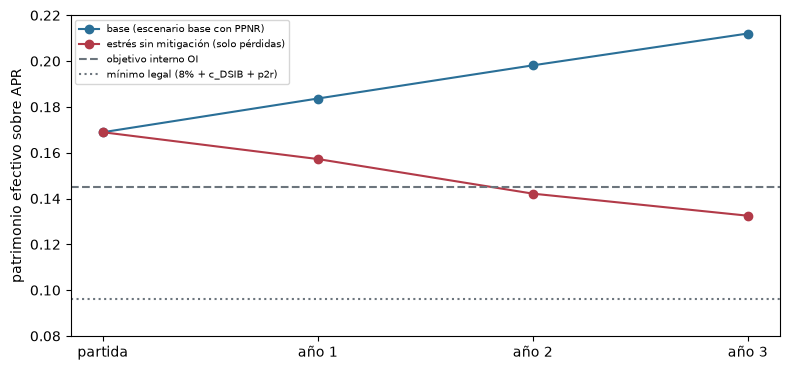

In [10]:
# Dibujar la razón de patrimonio efectivo del caso base y del de estrés frente al objetivo interno y al mínimo legal
years = np.arange(0, 4)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(years, [start["pe_ratio"]] + [y.pe_pct for y in plan["base"]], marker="o", label="base (escenario base con PPNR)", color="#2a6f97")
ax.plot(years, [start["pe_ratio"]] + [y.pe_pct for y in plan["stress-without-mitigation"]], marker="o", label="estrés sin mitigación (solo pérdidas)", color="#b23a48")
ax.axhline(oi.oi, color="#6c757d", linestyle="--", label="objetivo interno OI")
ax.axhline(legal_minimum, color="#6c757d", linestyle=":", label="mínimo legal (8% + c_DSIB + p2r)")
ax.set_xticks(years)
ax.set_xticklabels(["partida"] + [f"año {k}" for k in (1, 2, 3)])
ax.set_ylabel("patrimonio efectivo sobre APR")
ax.set_ylim(0.08, 0.22)
ax.legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()

- **La trayectoria de CET1 de solo pérdidas cae de 11,00 a 9,83; 8,32 y 7,36 por ciento de los APR** (CLP 736.508; 623.333 y 551.141 millones) tras pérdidas con estrés de 87.706; 113.174 y 72.193 millones; la trayectoria del motor es igual a la versionada al dígito.
- **La fila rotulada de PPNR agrega unos CLP 147.000 millones al año** (147.813; 147.070 y 147.070) y sube la razón de CET1 a 11,80; 12,25 y 13,25 por ciento, por lo cual el capital principal es la trayectoria de solo pérdidas y la fila está rotulada: el ingreso descansa en dos razones declaradas y en una trayectoria de tasas, y no es una predicción.
- **El objetivo interno es 14,5 por ciento** (8 + 1,5 + 1,0 + 2,5 + 0,5 + 1,0), el requerimiento del artículo 66 quinquies es 0,125 por ciento, el mínimo legal es 9,625 por ciento y la pila de CET1 del estrés inverso es 9,0625 por ciento. El motor rechaza un requerimiento de 5 por ciento (tope 4) y una estimación propia de 1 por ciento bajo un requerimiento de 2.
- **El banco bajo estrés mantiene el mínimo legal y no alcanza su propio objetivo.** Sin mitigación la razón de patrimonio efectivo es 15,72; 14,21 y 13,25 por ciento: holgura sobre el mínimo legal de 6,10; 4,59 y 3,62 puntos y ningún déficit, pero +1,22; -0,29 y -1,25 puntos frente al objetivo interno de 14,5 por ciento. El caso base queda 3,9 a 6,7 puntos sobre él. El caso con mitigación es igual al sin ella porque no se supone ninguna acción.
- **La regla estática se aplica tal como está escrita.** La nueva exposición de etapa 3 de CLP 1.131.441 millones en doce trimestres lleva la etapa 3 de 141.229 a 1.272.670 millones mientras el total se mantiene constante, y la prueba del motor es verde con 12 períodos, como en el documento versionado. Con una cura plantada es roja con `no-cure`; con un total cambiado, roja con `constant-total`.
- **La aproximación de P2G es cero**: la mayor caída de CET1/APR, 3,64 puntos, queda bajo los 4,0 puntos de colchones utilizables. Es una aproximación rotulada de Contraste y no un requerimiento.
- **Las 34 filas del Anexo 3 reconstruidas con el motor son idénticas a las versionadas** (la fila 10.1, la caída de la razón de CET1 en el estrés, es 3,64 puntos; la fila 10.2 no aplica porque no se supone mitigación; la fila 12, la holgura del patrimonio efectivo sobre el OI en el punto de partida, es 2,39 puntos).

Lo que este cuaderno no muestra: el NII detrás del PPNR se leyó, no se recalculó, porque necesita la cartera de tasas de interés del caso C15; el capital y los APR son anclas de un banco sintético, así que ninguna de estas razones describe un banco real; y la pérdida con estrés es un piso, porque el riesgo de mercado y el operacional llevan solo su pérdida esperada en todo escenario.

## Resumen

- La trayectoria de CET1 principal es el CET1 inicial menos las pérdidas con estrés acumuladas, sin inventar ingresos; el PPNR es una fila rotulada con dos razones declaradas.
- El objetivo interno OI suma el mínimo de 8 por ciento, los colchones, la estimación propia de Pilar 2 del banco y un colchón voluntario; el tope de 4 por ciento limita el requerimiento del artículo 66 quinquies, nunca la estimación propia, y el motor rechaza ambos errores.
- `capital_plan` corre base, estrés y estrés con mitigación sobre un balance estático; en el escenario severamente adverso el mínimo legal se mantiene en todos los años y el objetivo interno no.
- Las reglas de balance estático de la EBA (total constante, nada sale de la etapa 3) las aplica `eba_static_balance_sheet` y las comprueba una prueba que nombra una cura plantada y un total cambiado.
- La cifra de P2G es una aproximación rotulada de Contraste, y las 34 filas del Anexo 3 reconstruidas con el motor son idénticas a las versionadas.

**Qué probar a continuación.** Cambia `c_d`, el colchón voluntario, a cero en el paso 3 y mira cómo se mueven el objetivo interno y su holgura; luego sigue con el cuaderno 06, que hace la pregunta inversa: qué escenario llevaría al banco al mínimo legal.

## Referencias

- EBA (2025), 2025 EU-wide stress test, Methodological Note del 2025-01-20: el balance estático (párrafos 24, 33, 34 y 90 a 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- CMF Chile (2025), Circular 2.365 y Anexo 3 del autoevaluación de capital (IAPE), el formulario resumen de 34 filas. https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- Dossier 03 de la investigación persistida de Contraste (la pila de capital chilena en 2026, el objetivo interno de capital y las pruebas de estrés dentro del IAPE), resumido en la base de investigación del SDD.
- Este repositorio: `docs/contracts/engine/stress-api.md` (el motor de capital) y `docs/design/features/c18/design.md`.